# Absorption v2 — Threshold & Parameter Analysis

**Three modes** — run any cell independently:

| Cell | What it produces |
|------|------------------|
| **Cell A** | Per-instrument heatmap (z_delta × z_price grid) + score distribution |
| **Cell B** | Per-structure pooled heatmap (all instruments in spread / jumbo combined) |
| **Cell C** | Per-instrument absorption_score threshold sweep table (Precision/Recall/F1/MCC) |

All three share the same labeling trick:
- Score every bar with `calculate_absorption_v2` (dummy thresholds so z_delta/z_price are computed everywhere)
- Run `label_absorption_atr` **twice** (once forcing BUY, once forcing SELL)
- Apply actual thresholds as masks at query time — **no re-labeling per threshold**

In [ ]:
import sys
from pathlib import Path
import numpy as np

project_root = r"C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents"
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from market_analysis.finding_threshold.absorption_v2_threshold import (
    run_heatmap_analysis,
    run_heatmap_by_structure,
    run_threshold_sweep,
)
from market_analysis.signals.absorption.calculate_rolling import (
    calculate_absorption_rolling,
)
print('Imports OK')

Imports OK


## Shared Parameters
Edit once here — all cells below read from these variables.

In [ ]:
# ── what to analyse ───────────────────────────────────────────────────────────
PRODUCT_CODE  = "SM"    # "SM" or "BO"
MONTHS_BACK   = 8       # calendar months of OHLC history to fetch
FRONT_N       = 5       # front-N spreads + front-N jumbos

# ── heatmap threshold grids ───────────────────────────────────────────────────
# X-axis: minimum |z_delta| required (higher = rarer, stronger signal)
DELTA_Z_GRID  = np.arange(1.0, 3.25, 0.25)

# Y-axis: maximum z_price allowed
# z_price measures MAGNITUDE of price move (it is based on abs(close-prev_close))
# Lower z_price = smaller-than-usual price move = stronger absorption
PRICE_Z_GRID  = np.arange(0.5, -1.75, -0.25)

# ── scorer params (v2 windows) ────────────────────────────────────────────────
V2_PARAMS = {
    "volume_window"   : 5,    # rolling avg volume lookback for delta normalisation
    "atr_window"      : 5,    # ATR lookback for price normalisation
    "baseline_window" : 15,   # median/MAD z-score baseline window
    # labeler
    "atr_period"      : 14,   # ATR period for stop/target levels
    "target_atr_mult" : 1.5,  # target = close ± ATR × this
    "stop_atr_mult"   : 1.5,  # stop   = close ∓ ATR × this
    "forward_days"    : 10,   # max days to scan forward for outcome
    # dummy thresholds — DO NOT change unless you want to pre-filter direction
    # setting these to 0 / 9999 means every bar gets z_delta and z_price computed
    "delta_z_threshold": 0,
    "price_z_threshold": 9999,
}

# ── sweep table params ────────────────────────────────────────────────────────
SCORE_GRID        = np.round(np.arange(0.05, 1.0, 0.05), 3)
MIN_SIGNAL_COUNT  = 8     # N < this is highlighted yellow in the table
N_BOOTSTRAP       = 500   # bootstrap resamples for Precision CI
RANDOM_SEED       = 42

print(f"Product : {PRODUCT_CODE}")
print(f"delta_z_grid : {DELTA_Z_GRID}")
print(f"price_z_grid : {PRICE_Z_GRID}")

Product : SM
delta_z_grid : [1.   1.25 1.5  1.75 2.   2.25 2.5  2.75 3.  ]
price_z_grid : [ 0.5   0.25  0.   -0.25 -0.5  -0.75 -1.   -1.25 -1.5 ]


## Cell A — Per-Instrument Heatmap + Score Distribution

For each instrument:
1. **Heatmap** — success rate at every (Δz threshold, Pz threshold) combination. Annotations show S/F/N counts and mean absorption_score.
2. **Distribution** — success vs failure histogram of the continuous `absorption_score`.


########################################################################
#  STRUCTURE : SPREAD  —  SM
########################################################################

──────────────────────────────────────────────────────────────────────
  SPREAD  ▶  SMV26-Z26  [1d]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.0 / 1.0
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  Bars fetched    : 187


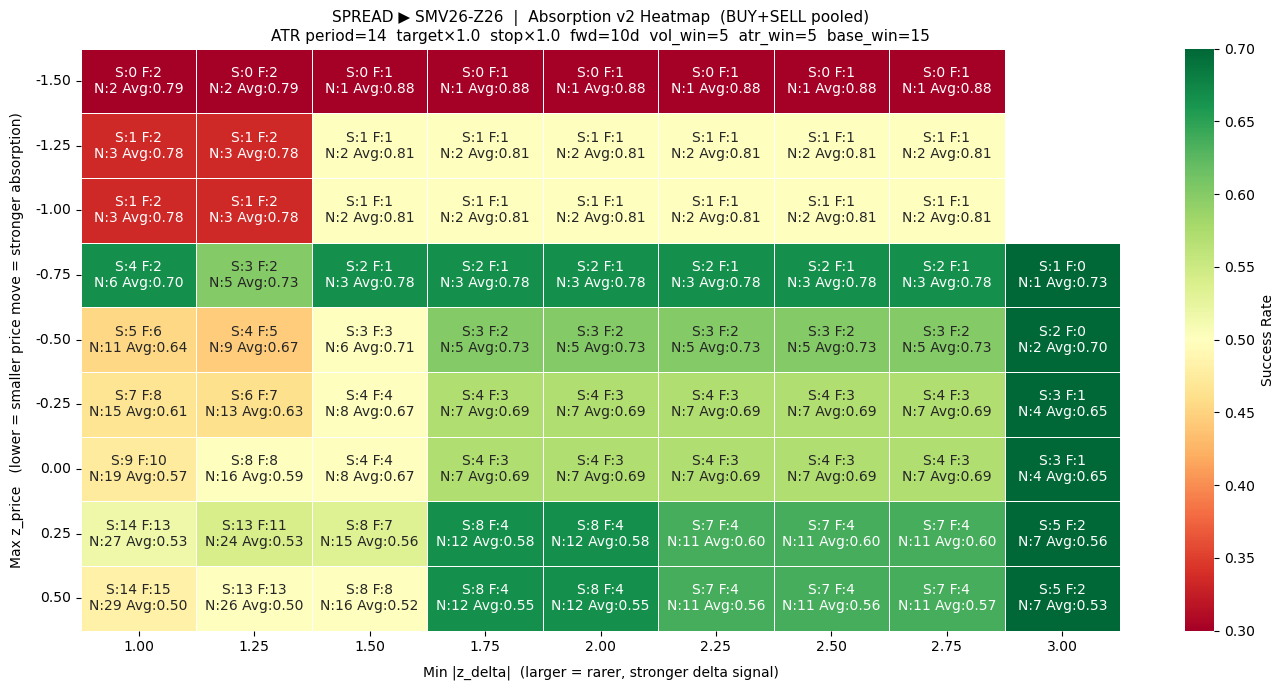

C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:373: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


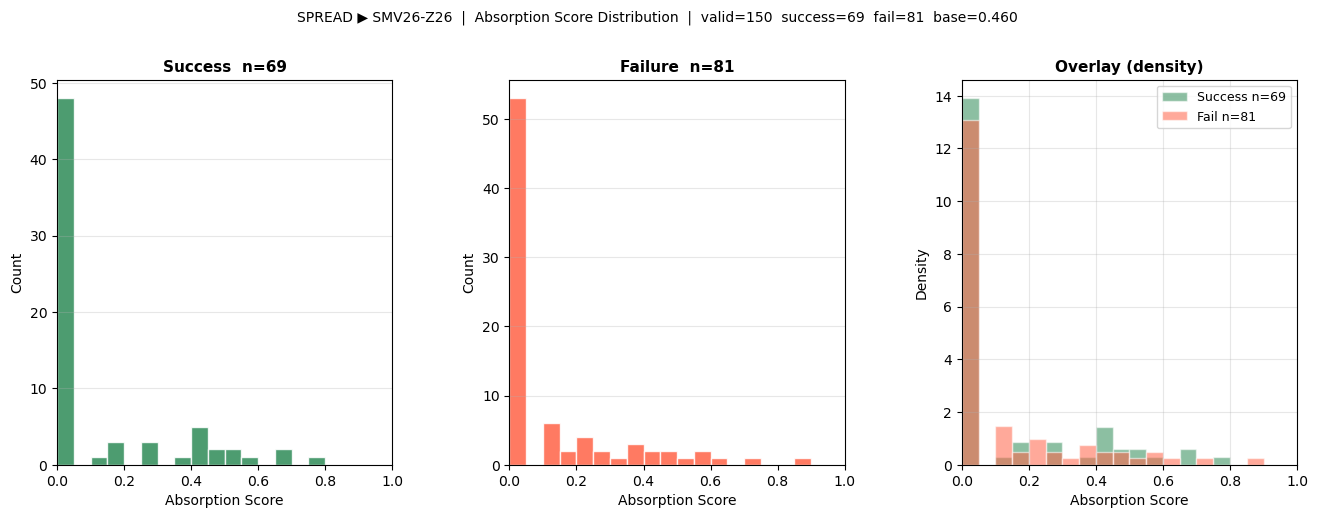


──────────────────────────────────────────────────────────────────────
  SPREAD  ▶  SMZ26-F27  [1d]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.0 / 1.0
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  Bars fetched    : 187


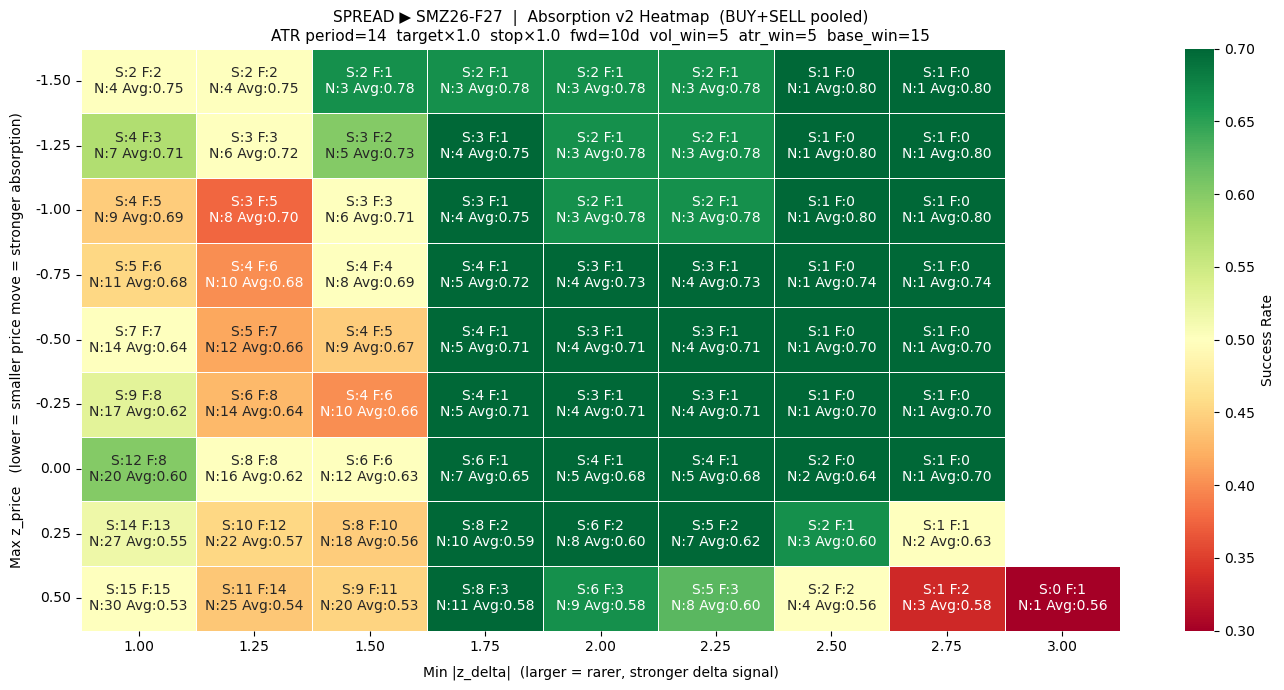

C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:373: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


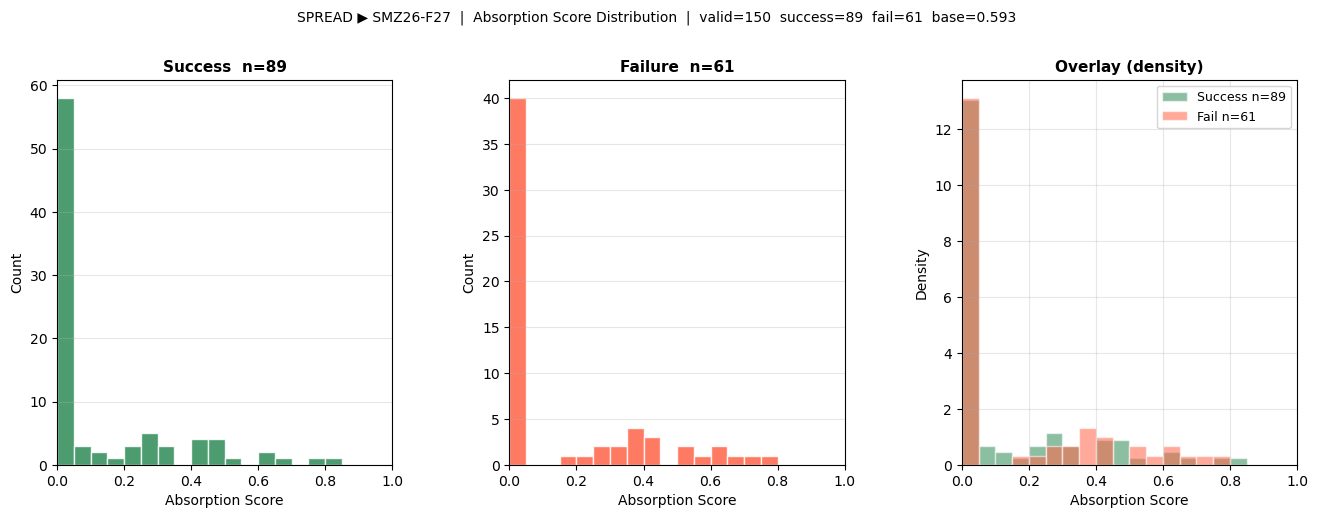


──────────────────────────────────────────────────────────────────────
  SPREAD  ▶  SMF27-H27  [1d]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.0 / 1.0
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  Bars fetched    : 186


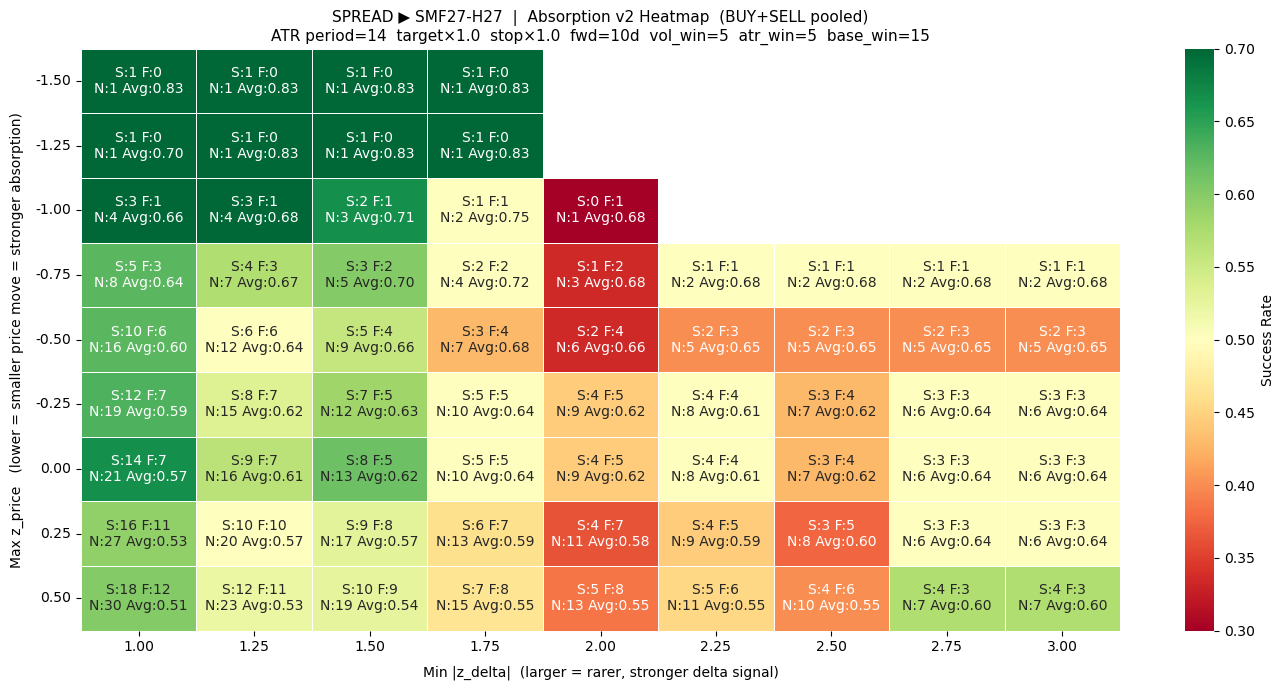

C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:373: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


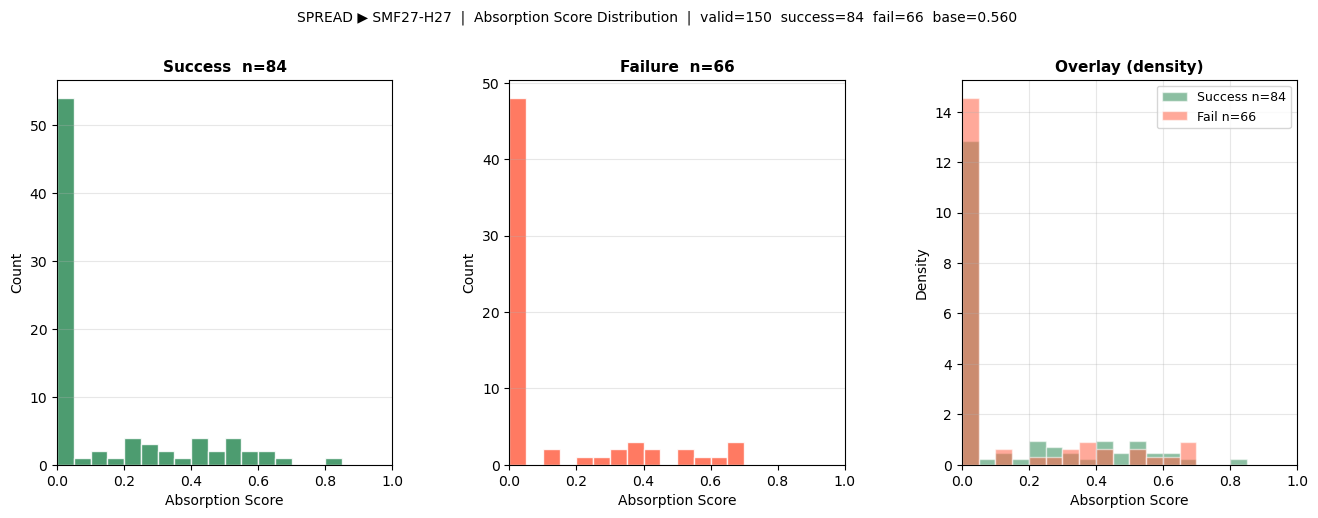


──────────────────────────────────────────────────────────────────────
  SPREAD  ▶  SMH27-K27  [1d]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.0 / 1.0
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  Bars fetched    : 182


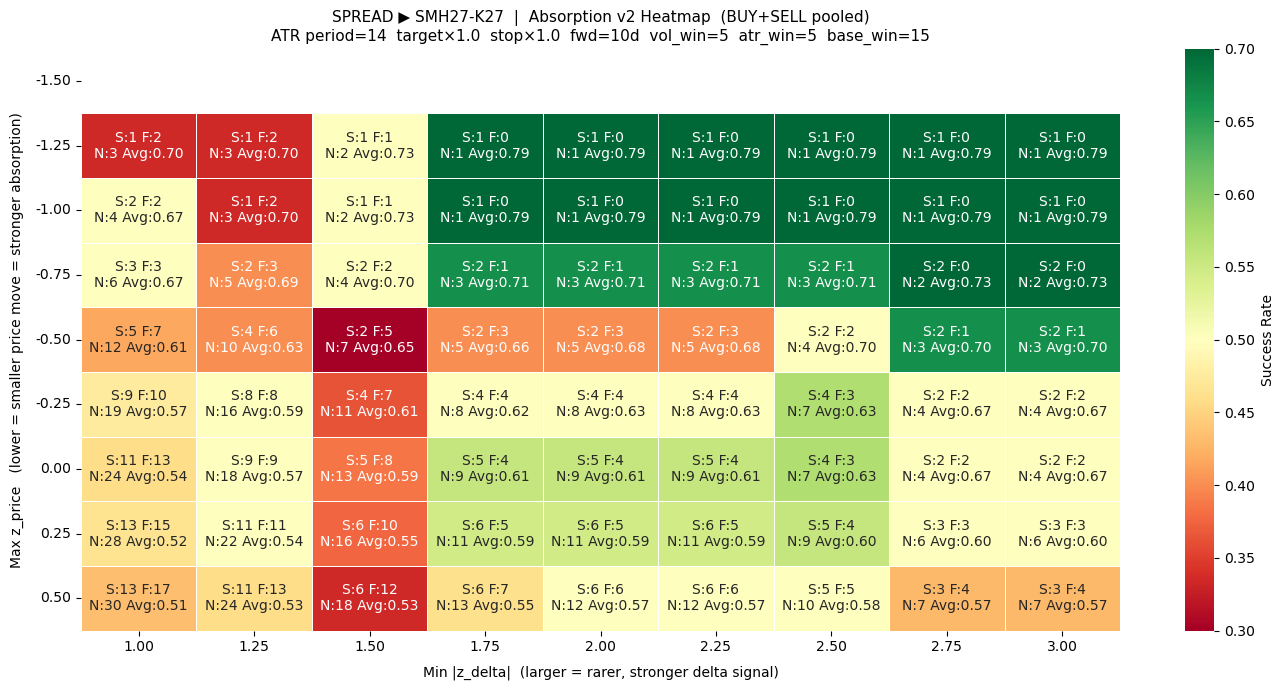

C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:373: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


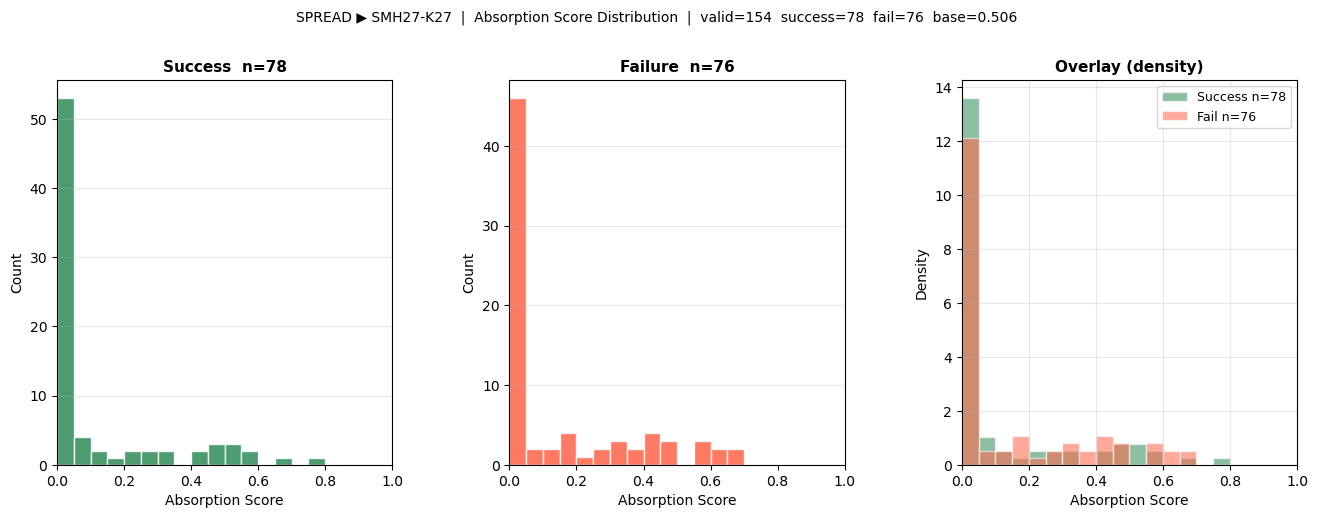


──────────────────────────────────────────────────────────────────────
  SPREAD  ▶  SMK27-N27  [1d]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.0 / 1.0
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  Bars fetched    : 174


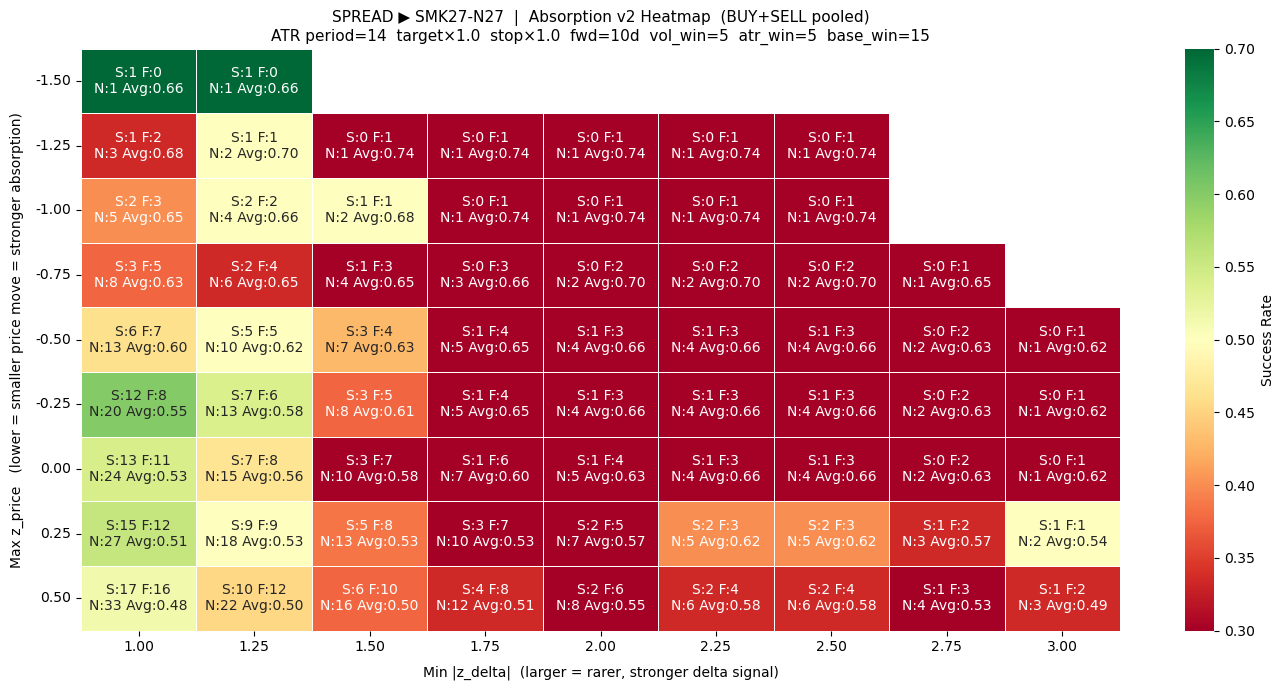

C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:373: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


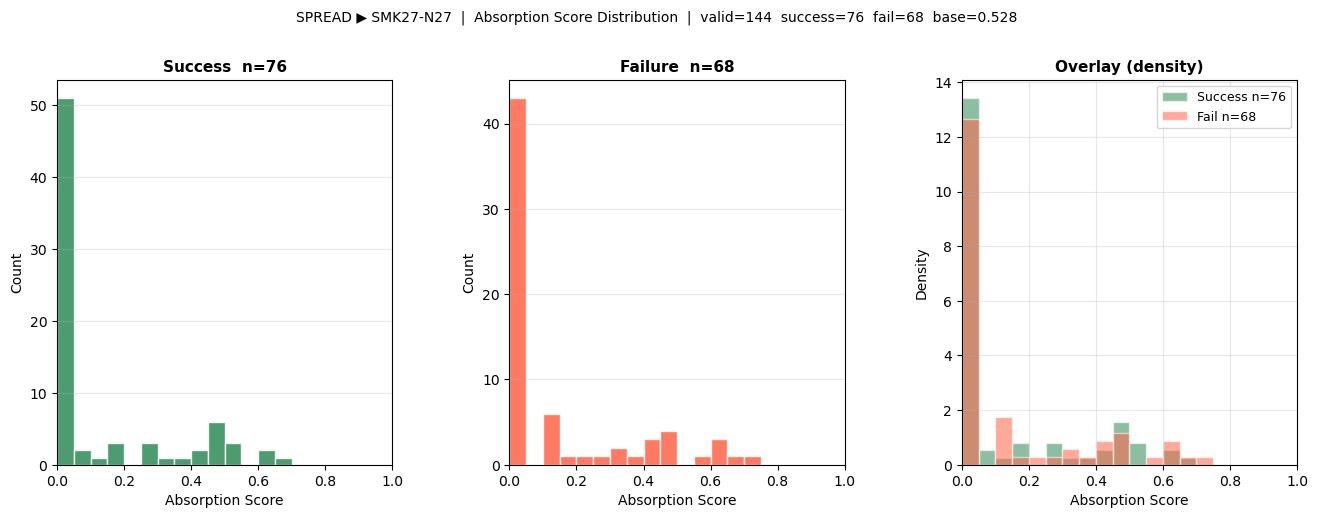


########################################################################
#  STRUCTURE : JUMBO  —  SM
########################################################################

──────────────────────────────────────────────────────────────────────
  JUMBO  ▶  SMV26-F27  [1d]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.0 / 1.0
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  Bars fetched    : 170


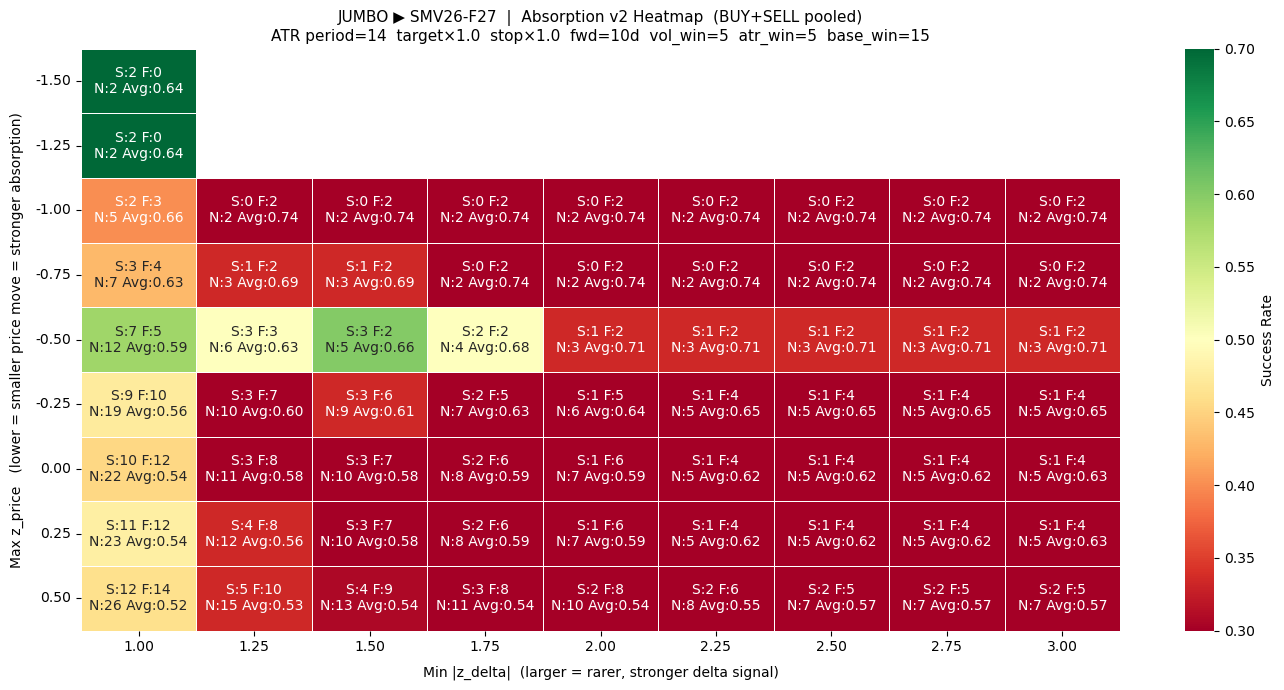

C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:373: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


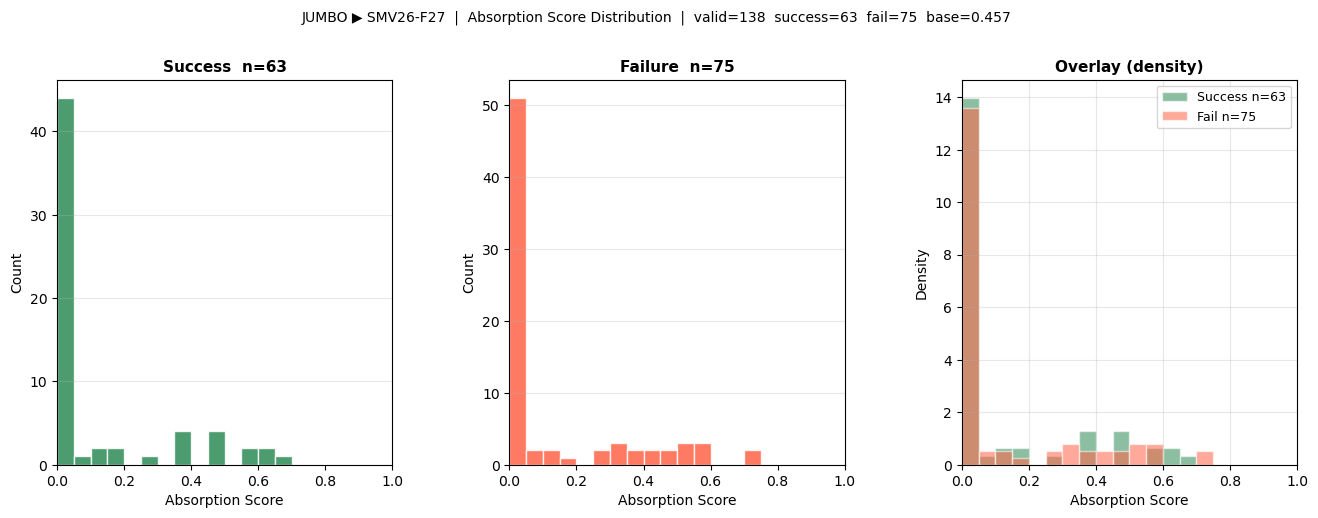


──────────────────────────────────────────────────────────────────────
  JUMBO  ▶  SMV26-H27  [1d]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.0 / 1.0
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  Bars fetched    : 148


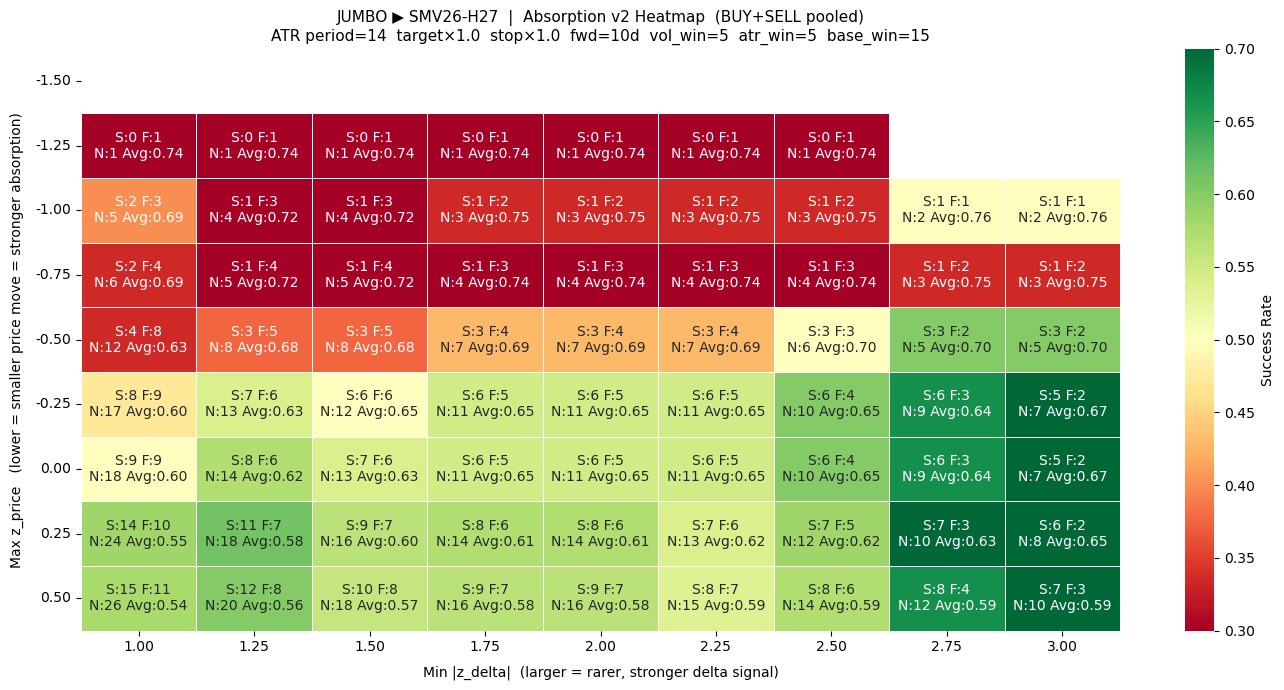

C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:373: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


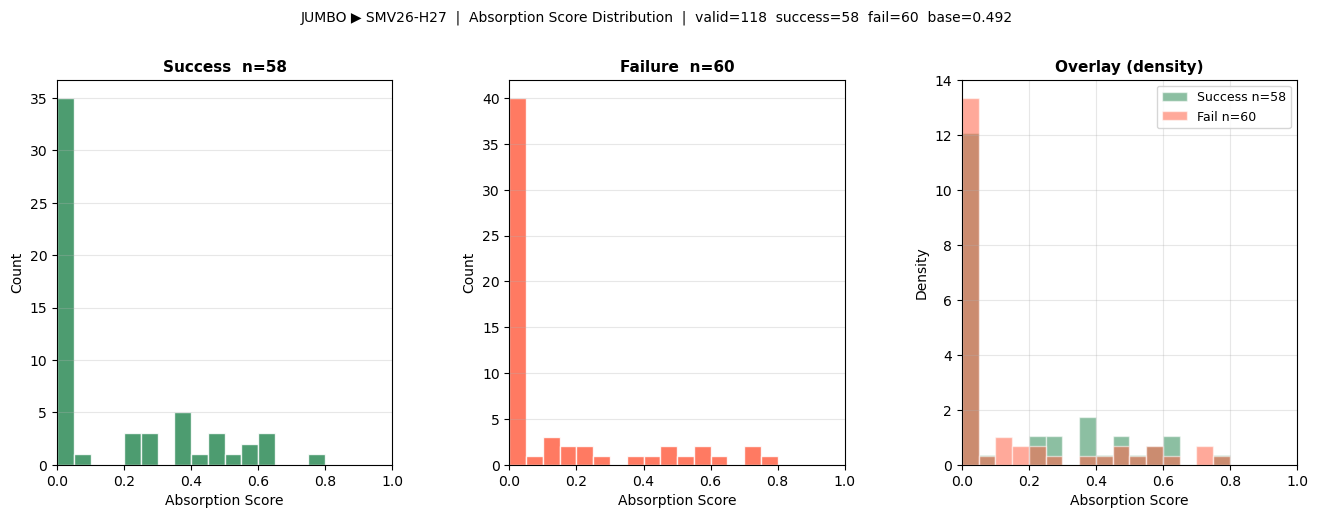


──────────────────────────────────────────────────────────────────────
  JUMBO  ▶  SMZ26-H27  [1d]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.0 / 1.0
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  Bars fetched    : 180


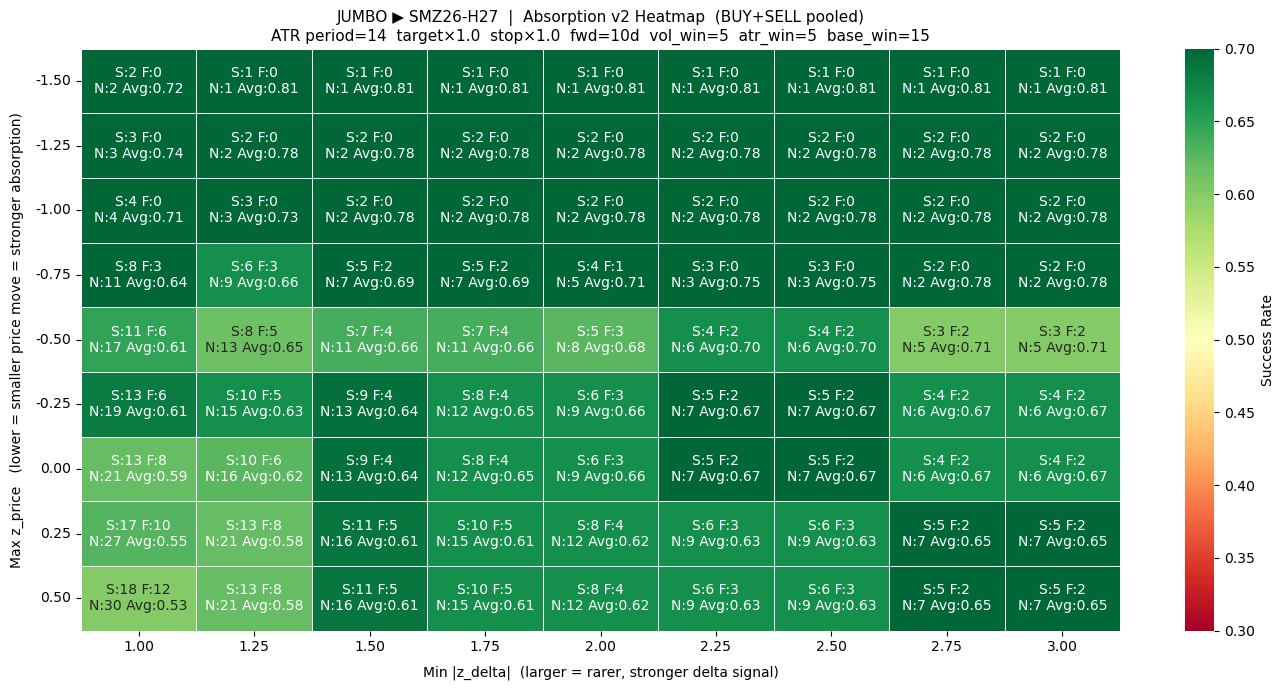

C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:373: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


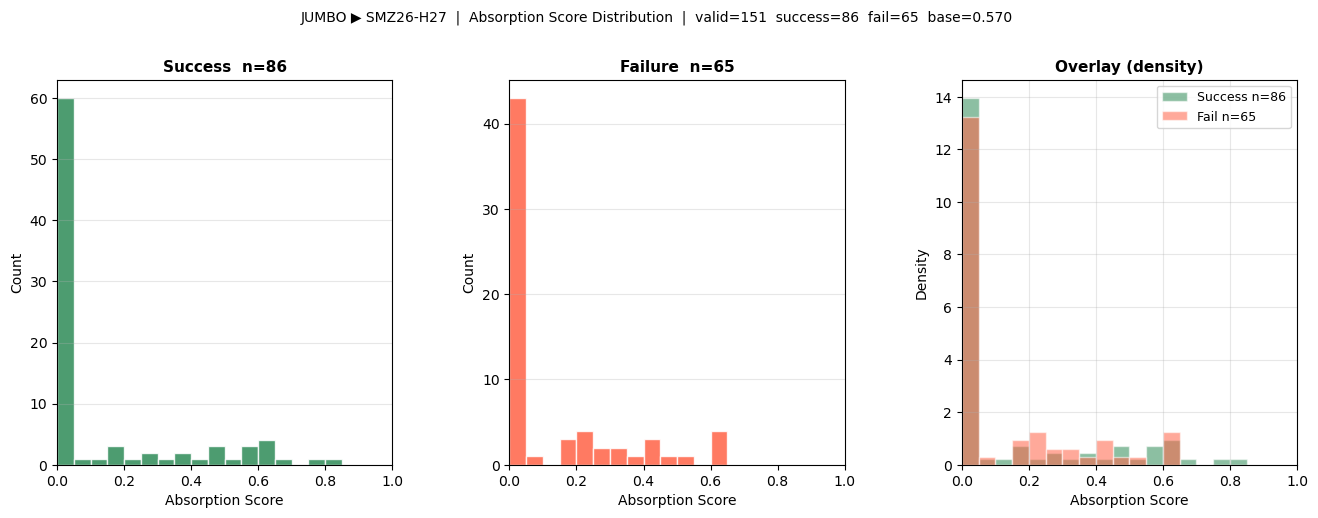


──────────────────────────────────────────────────────────────────────
  JUMBO  ▶  SMZ26-K27  [1d]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.0 / 1.0
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  Bars fetched    : 166


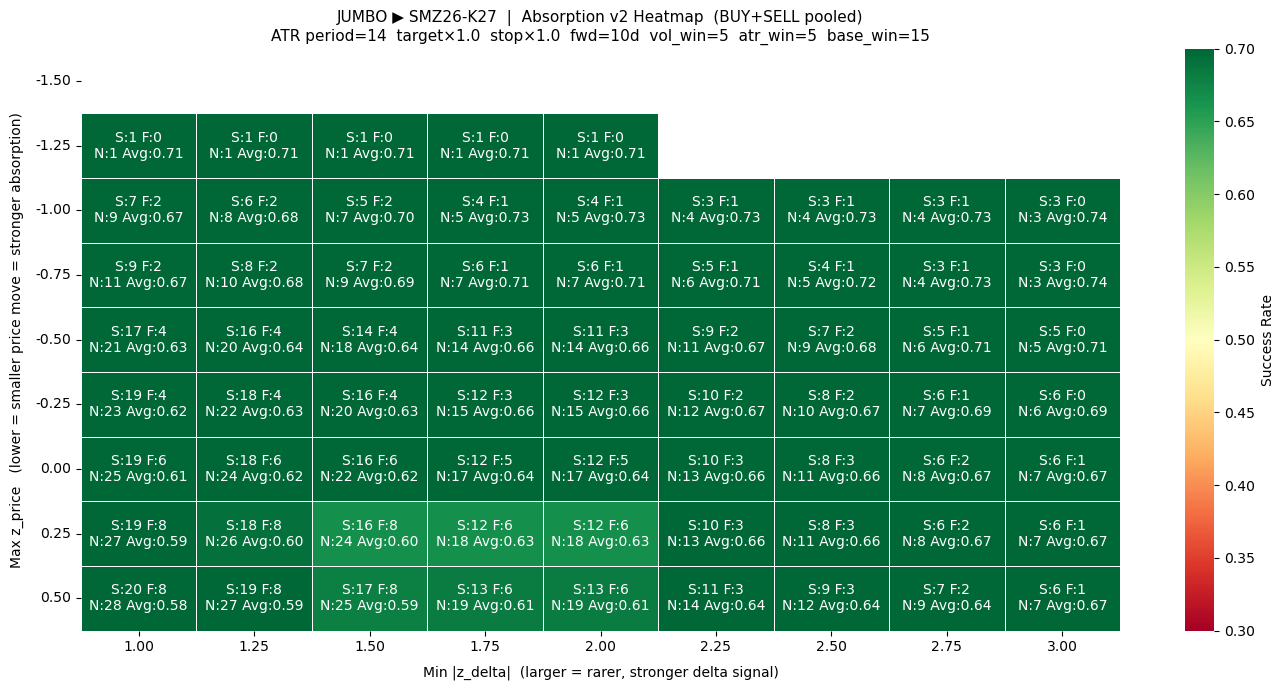

C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:373: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


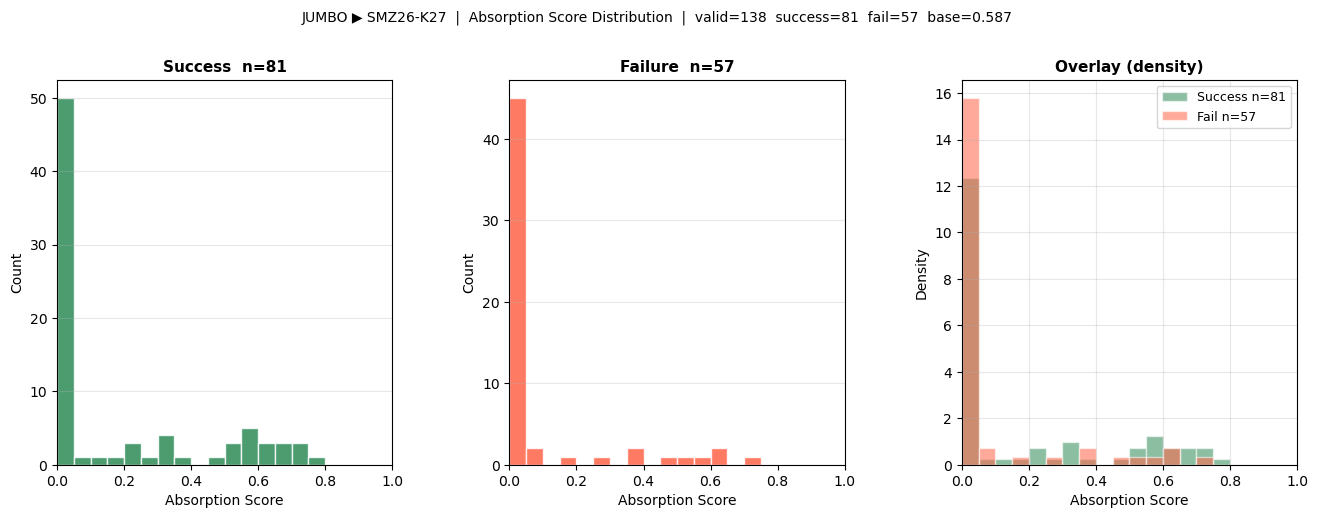


──────────────────────────────────────────────────────────────────────
  JUMBO  ▶  SMF27-K27  [1d]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.0 / 1.0
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  Bars fetched    : 147


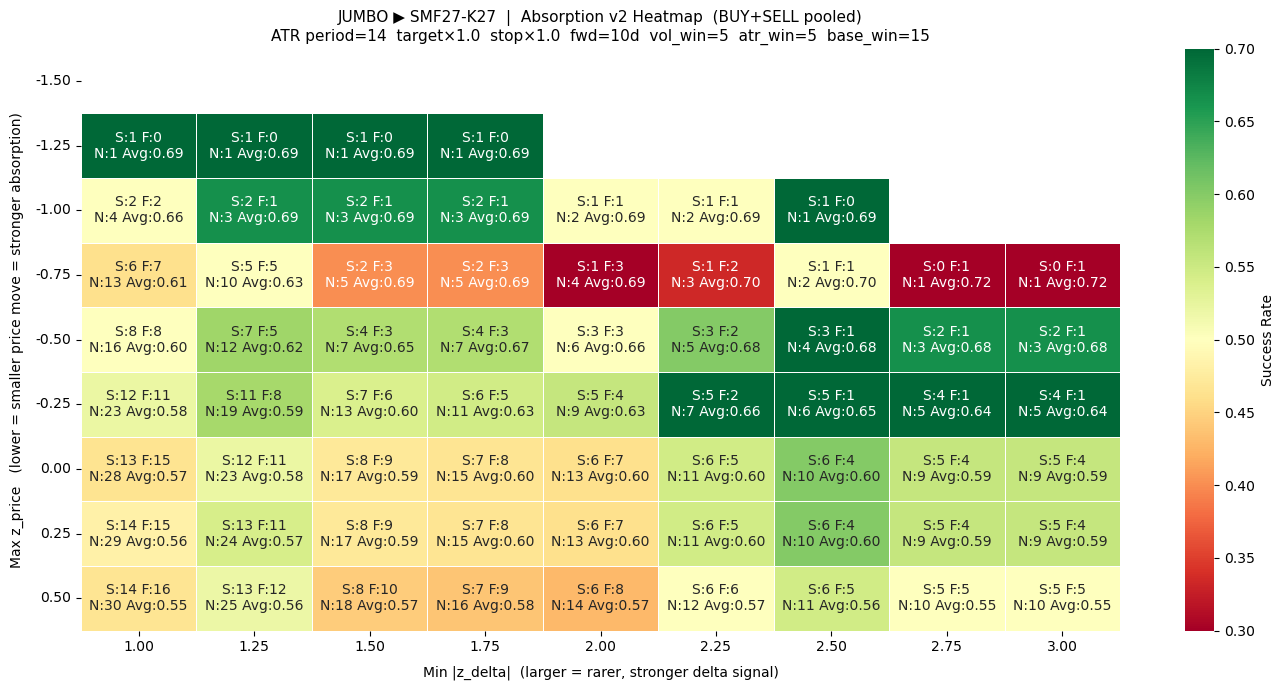

C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:373: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


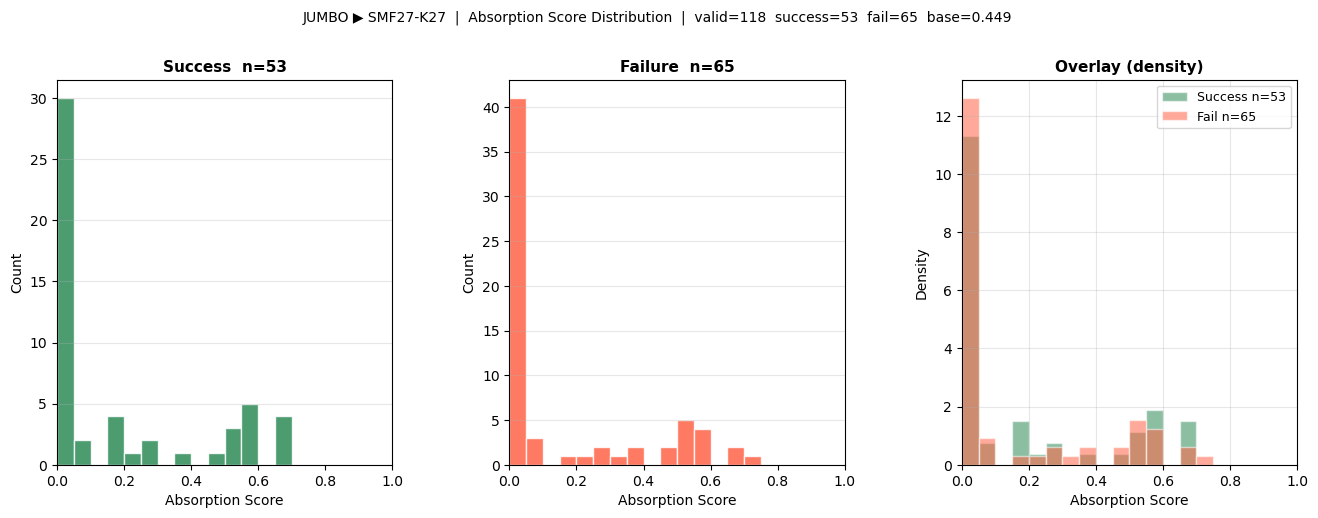

In [3]:
results_a = run_heatmap_analysis(
    product_code   = PRODUCT_CODE,
    months_back    = MONTHS_BACK,
    front_n        = FRONT_N,
    delta_z_grid   = DELTA_Z_GRID,
    price_z_grid   = PRICE_Z_GRID,
    params         = V2_PARAMS,
    show_heatmap   = True,
    show_dist_plot = True,
)

## Cell B — Pooled Heatmap per Structure (Spread / Jumbo)

Same heatmap as Cell A but all instruments within each structure type are pooled into one matrix. Reduces per-instrument noise and gives a cleaner signal quality picture at the structure level.


########################################################################
#  POOLED HEATMAP — SPREAD  (SM)
########################################################################
  Loading SMV26-Z26...
  Loading SMZ26-F27...
  Loading SMF27-H27...
  Loading SMH27-K27...
  Loading SMK27-N27...


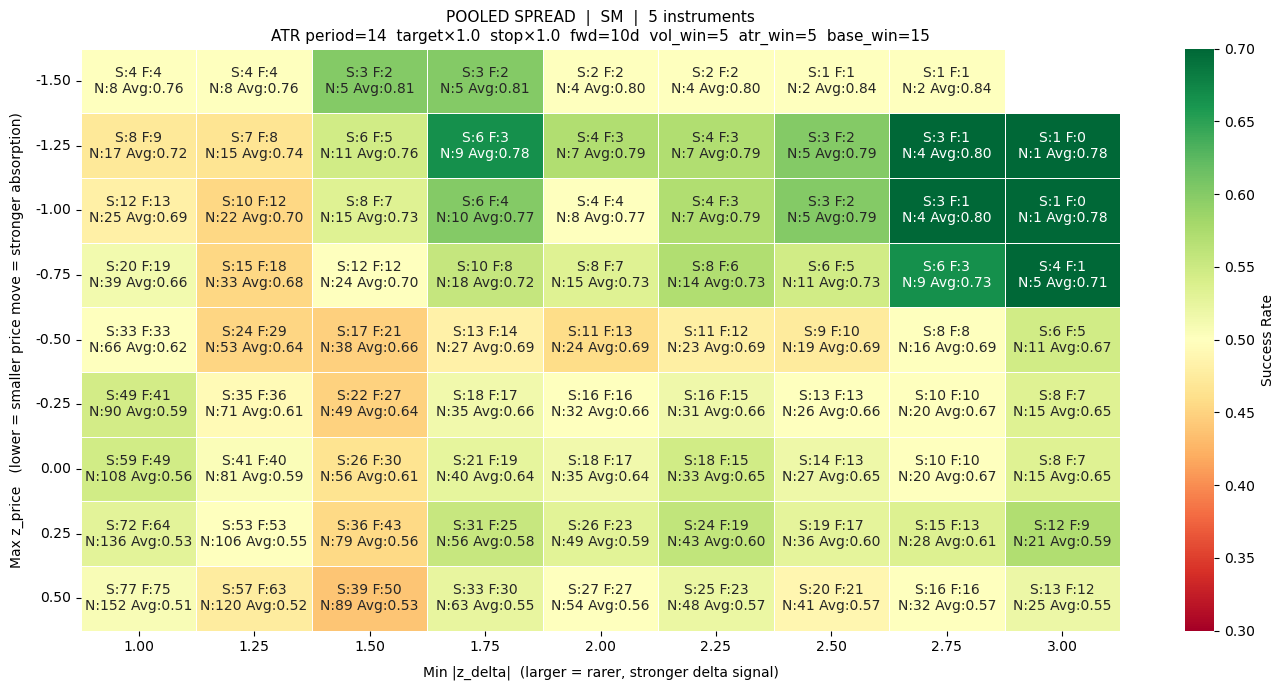


########################################################################
#  POOLED HEATMAP — JUMBO  (SM)
########################################################################
  Loading SMV26-F27...
  Loading SMV26-H27...
  Loading SMZ26-H27...
  Loading SMZ26-K27...
  Loading SMF27-K27...


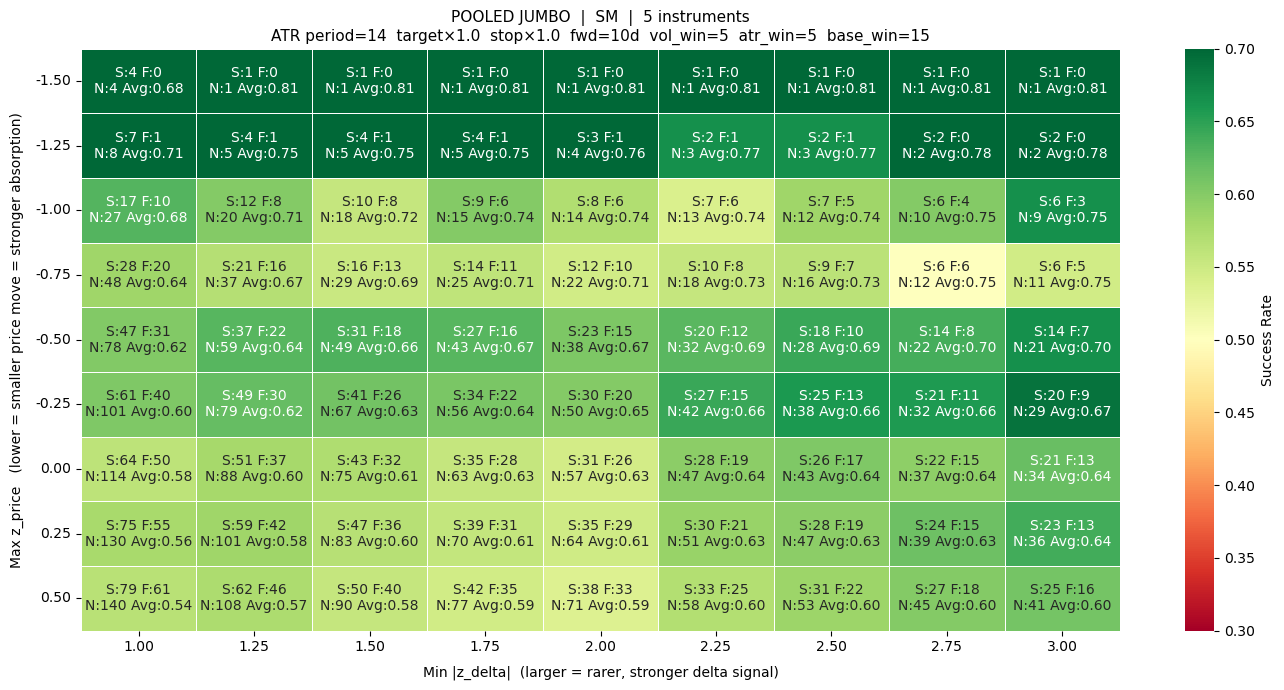

In [4]:
results_b = run_heatmap_by_structure(
    product_code   = PRODUCT_CODE,
    months_back    = MONTHS_BACK,
    front_n        = FRONT_N,
    delta_z_grid   = DELTA_Z_GRID,
    price_z_grid   = PRICE_Z_GRID,
    params         = V2_PARAMS,
    show_heatmap   = True,
    show_dist_plot = False,   # no per-instrument distributions in pooled mode
)

## Cell C — Absorption Score Threshold Sweep Table

Sweeps the **continuous `absorption_score`** (not the z-thresholds) and computes
Precision / Precision CI (bootstrap) / Recall / F1 / MCC / Lift at each cut-off.

Yellow rows = N < MIN_SIGNAL_COUNT (statistically unreliable).


########################################################################
#  STRUCTURE : SPREAD  —  SM  (threshold sweep)
########################################################################

──────────────────────────────────────────────────────────────────────
  SPREAD  ▶  SMV26-Z26  [1d]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.0 / 1.0
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  BUY   directional bars=88  valid outcomes=75  success_rate=0.520
  SELL  directional bars=81  valid outcomes=75  success_rate=0.400

  Threshold sweep  (base=0.460  PR-AUC=0.461)


,Score Thresh,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.050,49,0.429,"[0.288,0.596]",0.304,0.356,-0.044,0.932,21,28,48,53,False
1,0.100,49,0.429,"[0.288,0.596]",0.304,0.356,-0.044,0.932,21,28,48,53,False
2,0.150,42,0.476,"[0.333,0.659]",0.290,0.360,0.020,1.035,20,22,49,59,False
3,0.200,37,0.459,"[0.311,0.658]",0.246,0.321,-0.001,0.999,17,20,52,61,False
4,0.250,33,0.515,"[0.338,0.700]",0.246,0.333,0.059,1.120,17,16,52,65,False
5,0.300,28,0.500,"[0.312,0.708]",0.203,0.289,0.038,1.087,14,14,55,67,False
6,0.350,27,0.519,"[0.333,0.740]",0.203,0.292,0.055,1.127,14,13,55,68,False
7,0.400,23,0.565,"[0.368,0.775]",0.188,0.283,0.090,1.229,13,10,56,71,False
8,0.450,16,0.500,"[0.250,0.750]",0.116,0.188,0.028,1.087,8,8,61,73,False
9,0.500,12,0.500,"[0.235,0.778]",0.087,0.148,0.024,1.087,6,6,63,75,False


C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:373: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


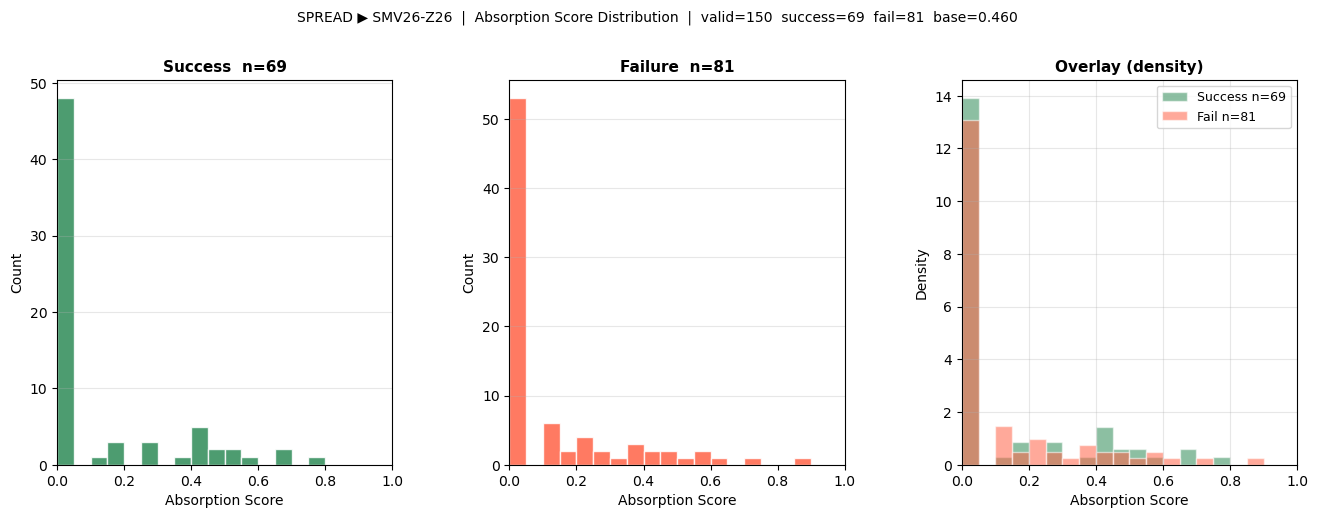


──────────────────────────────────────────────────────────────────────
  SPREAD  ▶  SMZ26-F27  [1d]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.0 / 1.0
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  BUY   directional bars=91  valid outcomes=81  success_rate=0.556
  SELL  directional bars=78  valid outcomes=69  success_rate=0.638

  Threshold sweep  (base=0.593  PR-AUC=0.582)


,Score Thresh,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.050,52,0.596,"[0.431,0.711]",0.348,0.440,0.004,1.005,31,21,58,40,False
1,0.100,49,0.571,"[0.398,0.696]",0.315,0.406,-0.031,0.963,28,21,61,40,False
2,0.150,47,0.553,"[0.384,0.681]",0.292,0.382,-0.055,0.932,26,21,63,40,False
3,0.200,45,0.556,"[0.377,0.699]",0.281,0.373,-0.050,0.936,25,20,64,41,False
4,0.250,41,0.537,"[0.341,0.688]",0.247,0.338,-0.071,0.904,22,19,67,42,False
5,0.300,34,0.500,"[0.306,0.706]",0.191,0.276,-0.103,0.843,17,17,72,44,False
6,0.350,29,0.483,"[0.263,0.727]",0.157,0.237,-0.110,0.814,14,15,75,46,False
7,0.400,25,0.560,"[0.333,0.780]",0.157,0.246,-0.030,0.944,14,11,75,50,False
8,0.450,18,0.556,"[0.289,0.815]",0.112,0.187,-0.028,0.936,10,8,79,53,False
9,0.500,14,0.429,"[0.154,0.774]",0.067,0.117,-0.108,0.722,6,8,83,53,False


C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:373: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


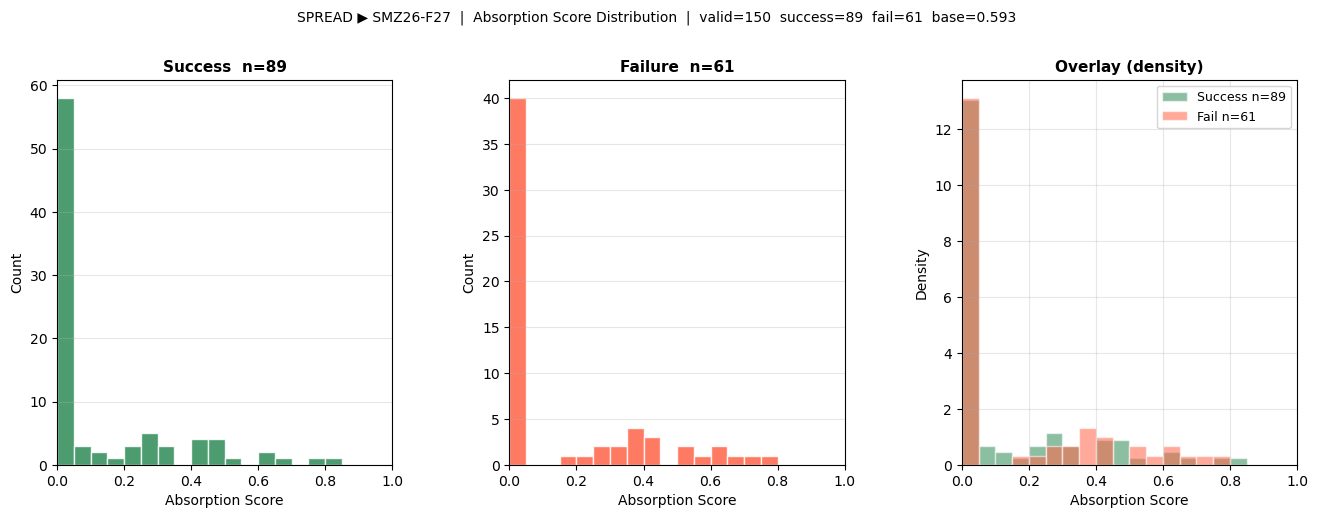


──────────────────────────────────────────────────────────────────────
  SPREAD  ▶  SMF27-H27  [1d]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.0 / 1.0
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  BUY   directional bars=79  valid outcomes=72  success_rate=0.542
  SELL  directional bars=84  valid outcomes=78  success_rate=0.577

  Threshold sweep  (base=0.560  PR-AUC=0.605)


,Score Thresh,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.050,48,0.625,"[0.462,0.714]",0.357,0.455,0.090,1.116,30,18,54,48,False
1,0.100,47,0.617,"[0.457,0.707]",0.345,0.443,0.078,1.102,29,18,55,48,False
2,0.150,43,0.628,"[0.474,0.747]",0.321,0.425,0.087,1.121,27,16,57,50,False
3,0.200,42,0.619,"[0.462,0.741]",0.310,0.413,0.074,1.105,26,16,58,50,False
4,0.250,37,0.595,"[0.429,0.718]",0.262,0.364,0.040,1.062,22,15,62,51,False
5,0.300,33,0.576,"[0.388,0.708]",0.226,0.325,0.017,1.028,19,14,65,52,False
6,0.350,29,0.586,"[0.375,0.714]",0.202,0.301,0.026,1.047,17,12,67,54,False
7,0.400,25,0.640,"[0.442,0.783]",0.190,0.294,0.072,1.143,16,9,68,57,False
8,0.450,19,0.632,"[0.400,0.769]",0.143,0.233,0.055,1.128,12,7,72,59,False
9,0.500,17,0.588,"[0.270,0.750]",0.119,0.198,0.020,1.050,10,7,74,59,False


C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:373: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


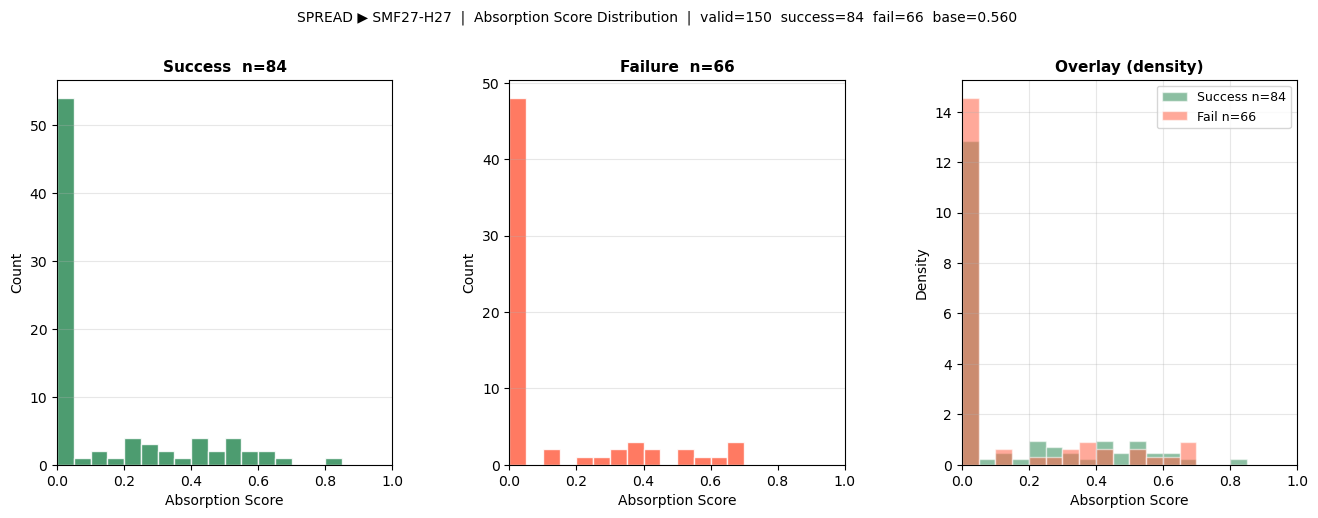


──────────────────────────────────────────────────────────────────────
  SPREAD  ▶  SMH27-K27  [1d]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.0 / 1.0
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  BUY   directional bars=86  valid outcomes=80  success_rate=0.438
  SELL  directional bars=78  valid outcomes=74  success_rate=0.581

  Threshold sweep  (base=0.506  PR-AUC=0.479)


,Score Thresh,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.050,55,0.455,"[0.353,0.569]",0.321,0.376,-0.077,0.897,25,30,53,46,False
1,0.100,49,0.429,"[0.326,0.531]",0.269,0.331,-0.106,0.846,21,28,57,48,False
2,0.150,45,0.422,"[0.325,0.541]",0.244,0.309,-0.108,0.834,19,26,59,50,False
3,0.200,40,0.450,"[0.347,0.570]",0.231,0.305,-0.067,0.888,18,22,60,54,False
4,0.250,37,0.432,"[0.325,0.571]",0.205,0.278,-0.083,0.854,16,21,62,55,False
5,0.300,33,0.424,"[0.333,0.558]",0.179,0.252,-0.086,0.838,14,19,64,57,False
6,0.350,28,0.429,"[0.310,0.600]",0.154,0.226,-0.073,0.846,12,16,66,60,False
7,0.400,26,0.462,"[0.333,0.640]",0.154,0.231,-0.041,0.911,12,14,66,62,False
8,0.450,20,0.500,"[0.333,0.675]",0.128,0.204,-0.005,0.987,10,10,68,66,False
9,0.500,14,0.500,"[0.261,0.692]",0.090,0.152,-0.004,0.987,7,7,71,69,False


C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:373: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


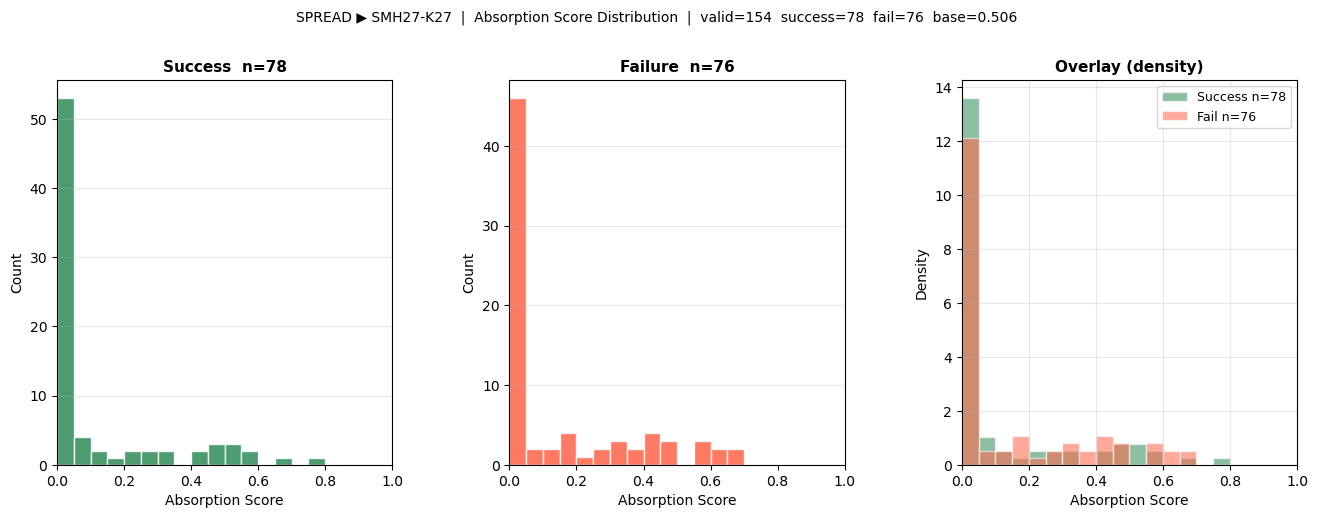


──────────────────────────────────────────────────────────────────────
  SPREAD  ▶  SMK27-N27  [1d]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.0 / 1.0
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  BUY   directional bars=72  valid outcomes=68  success_rate=0.559
  SELL  directional bars=84  valid outcomes=76  success_rate=0.500

  Threshold sweep  (base=0.528  PR-AUC=0.517)


,Score Thresh,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.050,50,0.500,"[0.393,0.614]",0.329,0.397,-0.041,0.947,25,25,51,43,False
1,0.100,48,0.479,"[0.373,0.596]",0.303,0.371,-0.069,0.908,23,25,53,43,False
2,0.150,41,0.537,"[0.423,0.652]",0.289,0.376,0.011,1.017,22,19,54,49,False
3,0.200,37,0.514,"[0.382,0.649]",0.250,0.336,-0.017,0.973,19,18,57,50,False
4,0.250,36,0.528,"[0.387,0.681]",0.250,0.339,0.000,1.000,19,17,57,51,False
5,0.300,32,0.500,"[0.355,0.677]",0.211,0.296,-0.030,0.947,16,16,60,52,False
6,0.350,29,0.517,"[0.361,0.690]",0.197,0.286,-0.011,0.980,15,14,61,54,False
7,0.400,27,0.519,"[0.373,0.679]",0.184,0.272,-0.009,0.982,14,13,62,55,False
8,0.450,22,0.545,"[0.385,0.750]",0.158,0.245,0.015,1.033,12,10,64,58,False
9,0.500,12,0.500,"[0.200,0.782]",0.079,0.136,-0.017,0.947,6,6,70,62,False


C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:373: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


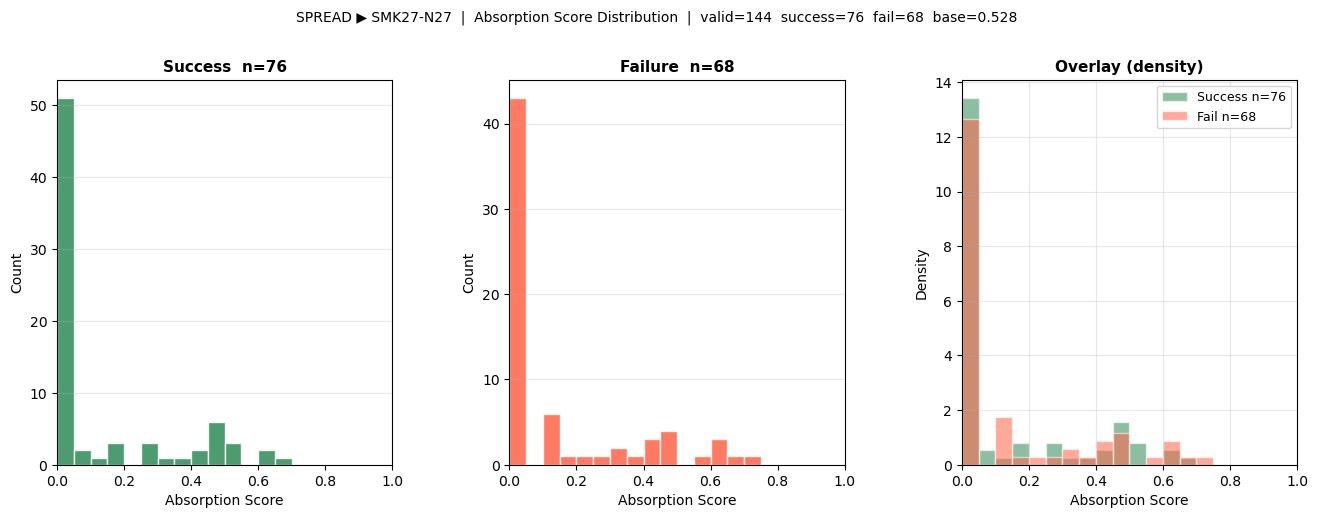


########################################################################
#  STRUCTURE : JUMBO  —  SM  (threshold sweep)
########################################################################

──────────────────────────────────────────────────────────────────────
  JUMBO  ▶  SMV26-F27  [1d]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.0 / 1.0
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  BUY   directional bars=74  valid outcomes=62  success_rate=0.435
  SELL  directional bars=78  valid outcomes=76  success_rate=0.474

  Threshold sweep  (base=0.457  PR-AUC=0.454)


,Score Thresh,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.050,43,0.442,"[0.311,0.643]",0.302,0.358,-0.020,0.968,19,24,44,51,False
1,0.100,40,0.450,"[0.320,0.645]",0.286,0.350,-0.008,0.986,18,22,45,53,False
2,0.150,36,0.444,"[0.311,0.667]",0.254,0.323,-0.014,0.974,16,20,47,55,False
3,0.200,33,0.424,"[0.257,0.667]",0.222,0.292,-0.036,0.929,14,19,49,56,False
4,0.250,33,0.424,"[0.257,0.667]",0.222,0.292,-0.036,0.929,14,19,49,56,False
5,0.300,30,0.433,"[0.250,0.706]",0.206,0.280,-0.025,0.949,13,17,50,58,False
6,0.350,27,0.481,"[0.283,0.755]",0.206,0.289,0.025,1.055,13,14,50,61,False
7,0.400,21,0.429,"[0.209,0.718]",0.143,0.214,-0.024,0.939,9,12,54,63,False
8,0.450,19,0.474,"[0.229,0.750]",0.143,0.220,0.014,1.038,9,10,54,65,False
9,0.500,13,0.385,"[0.121,0.750]",0.079,0.132,-0.047,0.842,5,8,58,67,False


C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:373: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


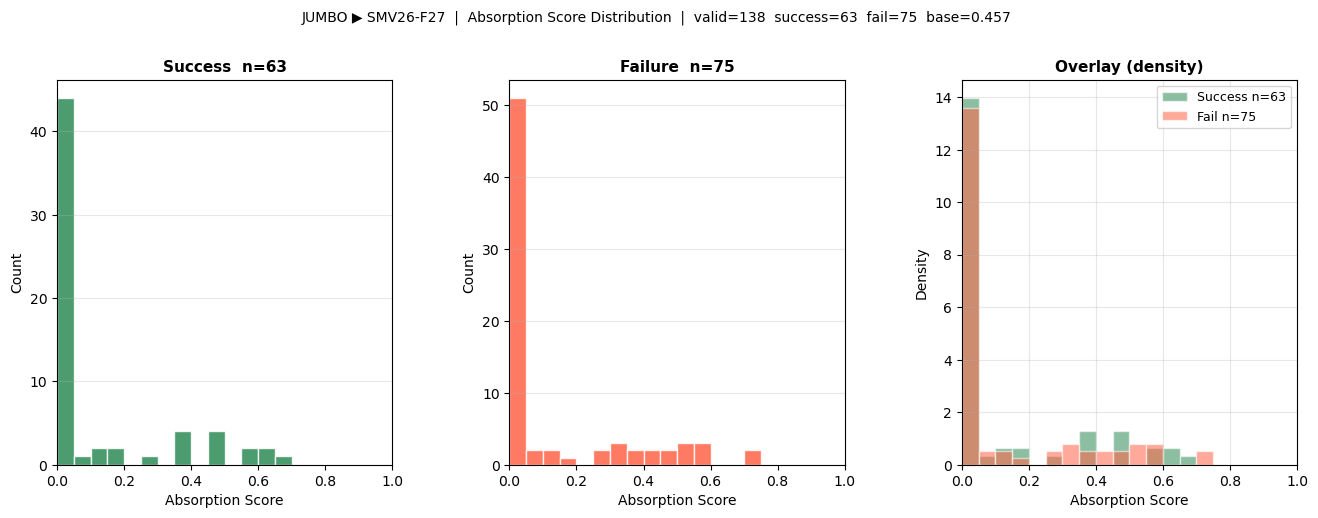


──────────────────────────────────────────────────────────────────────
  JUMBO  ▶  SMV26-H27  [1d]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.0 / 1.0
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  BUY   directional bars=64  valid outcomes=57  success_rate=0.509
  SELL  directional bars=66  valid outcomes=61  success_rate=0.475

  Threshold sweep  (base=0.492  PR-AUC=0.515)


,Score Thresh,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.050,43,0.535,"[0.359,0.685]",0.397,0.455,0.066,1.088,23,20,35,40,False
1,0.100,41,0.537,"[0.363,0.707]",0.379,0.444,0.066,1.092,22,19,36,41,False
2,0.150,38,0.579,"[0.406,0.737]",0.379,0.458,0.121,1.178,22,16,36,44,False
3,0.200,36,0.611,"[0.417,0.784]",0.379,0.468,0.158,1.243,22,14,36,46,False
4,0.250,31,0.613,"[0.400,0.776]",0.328,0.427,0.145,1.247,19,12,39,48,False
5,0.300,27,0.593,"[0.389,0.746]",0.276,0.376,0.110,1.206,16,11,42,49,False
6,0.350,27,0.593,"[0.389,0.746]",0.276,0.376,0.110,1.206,16,11,42,49,False
7,0.400,21,0.524,"[0.333,0.711]",0.190,0.278,0.030,1.066,11,10,47,50,False
8,0.450,19,0.526,"[0.333,0.744]",0.172,0.260,0.030,1.071,10,9,48,51,False
9,0.500,14,0.500,"[0.214,0.782]",0.121,0.194,0.006,1.017,7,7,51,53,False


C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:373: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


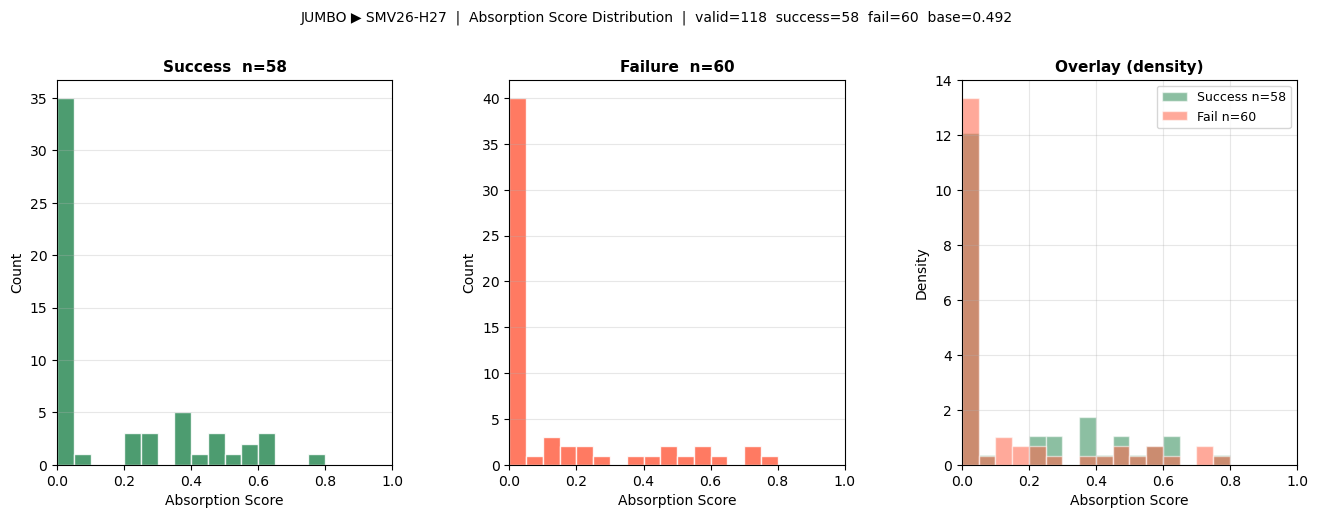


──────────────────────────────────────────────────────────────────────
  JUMBO  ▶  SMZ26-H27  [1d]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.0 / 1.0
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  BUY   directional bars=79  valid outcomes=73  success_rate=0.507
  SELL  directional bars=83  valid outcomes=78  success_rate=0.628

  Threshold sweep  (base=0.570  PR-AUC=0.606)


,Score Thresh,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.050,48,0.542,"[0.412,0.663]",0.302,0.388,-0.038,0.951,26,22,60,43,False
1,0.100,46,0.543,"[0.413,0.667]",0.291,0.379,-0.035,0.954,25,21,61,44,False
2,0.150,45,0.533,"[0.400,0.667]",0.279,0.366,-0.048,0.936,24,21,62,44,False
3,0.200,39,0.538,"[0.378,0.657]",0.244,0.336,-0.037,0.945,21,18,65,47,False
4,0.250,34,0.588,"[0.403,0.727]",0.233,0.333,0.020,1.033,20,14,66,51,False
5,0.300,30,0.600,"[0.414,0.774]",0.209,0.310,0.031,1.053,18,12,68,53,False
6,0.350,27,0.630,"[0.429,0.793]",0.198,0.301,0.057,1.106,17,10,69,55,False
7,0.400,24,0.625,"[0.435,0.783]",0.174,0.273,0.049,1.097,15,9,71,56,False
8,0.450,20,0.700,"[0.500,0.882]",0.163,0.264,0.103,1.229,14,6,72,59,False
9,0.500,16,0.688,"[0.455,0.923]",0.128,0.216,0.082,1.207,11,5,75,60,False


C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:373: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


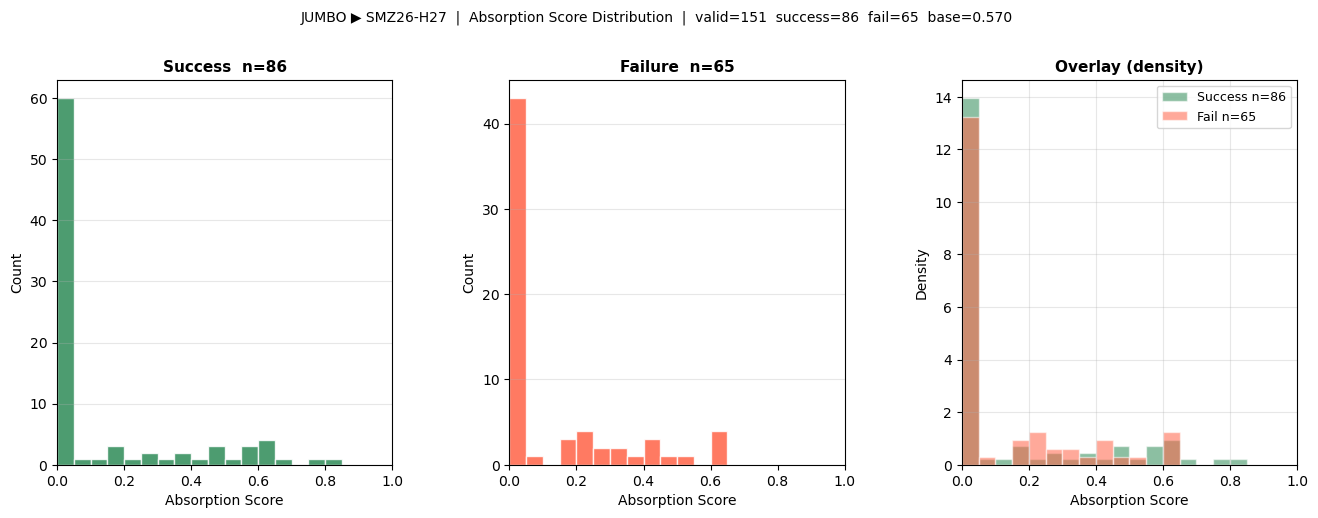


──────────────────────────────────────────────────────────────────────
  JUMBO  ▶  SMZ26-K27  [1d]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.0 / 1.0
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  BUY   directional bars=75  valid outcomes=71  success_rate=0.577
  SELL  directional bars=73  valid outcomes=67  success_rate=0.597

  Threshold sweep  (base=0.587  PR-AUC=0.715)


,Score Thresh,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.050,43,0.721,"[0.604,0.843]",0.383,0.500,0.183,1.228,31,12,50,45,False
1,0.100,40,0.750,"[0.638,0.861]",0.370,0.496,0.212,1.278,30,10,51,47,False
2,0.150,39,0.744,"[0.616,0.859]",0.358,0.483,0.200,1.267,29,10,52,47,False
3,0.200,37,0.757,"[0.636,0.888]",0.346,0.475,0.209,1.289,28,9,53,48,False
4,0.250,34,0.735,"[0.586,0.880]",0.309,0.435,0.172,1.253,25,9,56,48,False
5,0.300,32,0.750,"[0.586,0.900]",0.296,0.425,0.182,1.278,24,8,57,49,False
6,0.350,28,0.714,"[0.540,0.884]",0.247,0.367,0.130,1.217,20,8,61,49,False
7,0.400,25,0.760,"[0.580,0.944]",0.235,0.358,0.165,1.295,19,6,62,51,False
8,0.450,25,0.760,"[0.580,0.944]",0.235,0.358,0.165,1.295,19,6,62,51,False
9,0.500,23,0.783,"[0.617,0.954]",0.222,0.346,0.178,1.333,18,5,63,52,False


C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:373: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


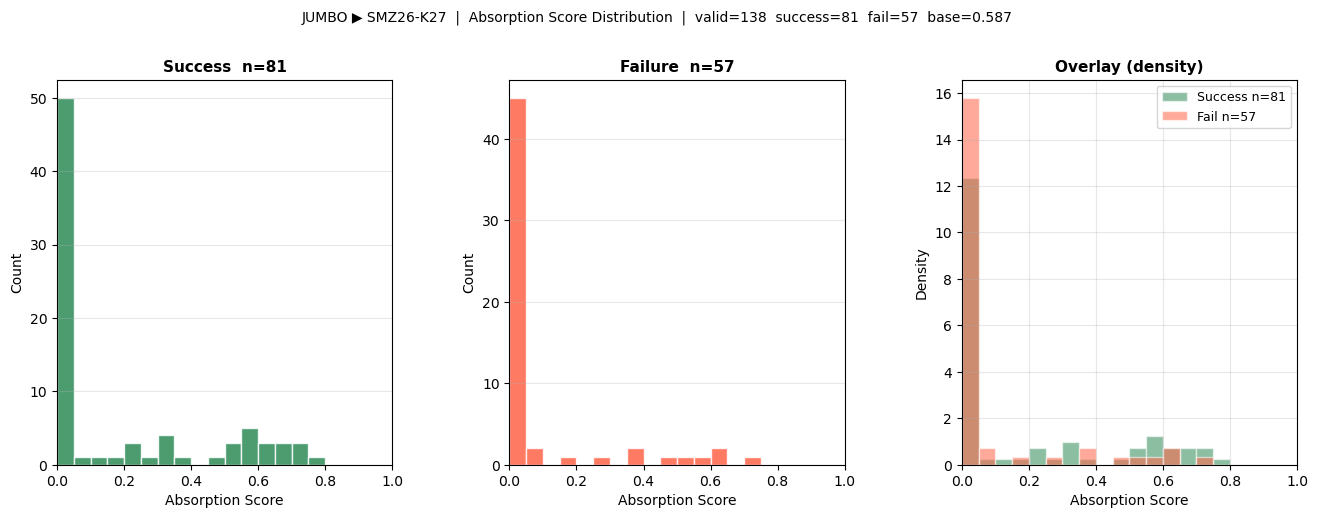


──────────────────────────────────────────────────────────────────────
  JUMBO  ▶  SMF27-K27  [1d]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.0 / 1.0
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  BUY   directional bars=67  valid outcomes=62  success_rate=0.403
  SELL  directional bars=62  valid outcomes=56  success_rate=0.500

  Threshold sweep  (base=0.449  PR-AUC=0.499)


,Score Thresh,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.050,47,0.489,"[0.303,0.618]",0.434,0.460,0.066,1.090,23,24,30,41,False
1,0.100,42,0.500,"[0.309,0.667]",0.396,0.442,0.076,1.113,21,21,32,44,False
2,0.150,42,0.500,"[0.309,0.667]",0.396,0.442,0.076,1.113,21,21,32,44,False
3,0.200,37,0.459,"[0.260,0.650]",0.321,0.378,0.014,1.023,17,20,36,45,False
4,0.250,35,0.457,"[0.257,0.667]",0.302,0.364,0.010,1.018,16,19,37,46,False
5,0.300,31,0.452,"[0.253,0.667]",0.264,0.333,0.003,1.005,14,17,39,48,False
6,0.350,30,0.467,"[0.267,0.686]",0.264,0.337,0.021,1.039,14,16,39,49,False
7,0.400,27,0.481,"[0.268,0.690]",0.245,0.325,0.035,1.072,13,14,40,51,False
8,0.450,27,0.481,"[0.268,0.690]",0.245,0.325,0.035,1.072,13,14,40,51,False
9,0.500,24,0.500,"[0.292,0.722]",0.226,0.312,0.052,1.113,12,12,41,53,False


C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:373: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


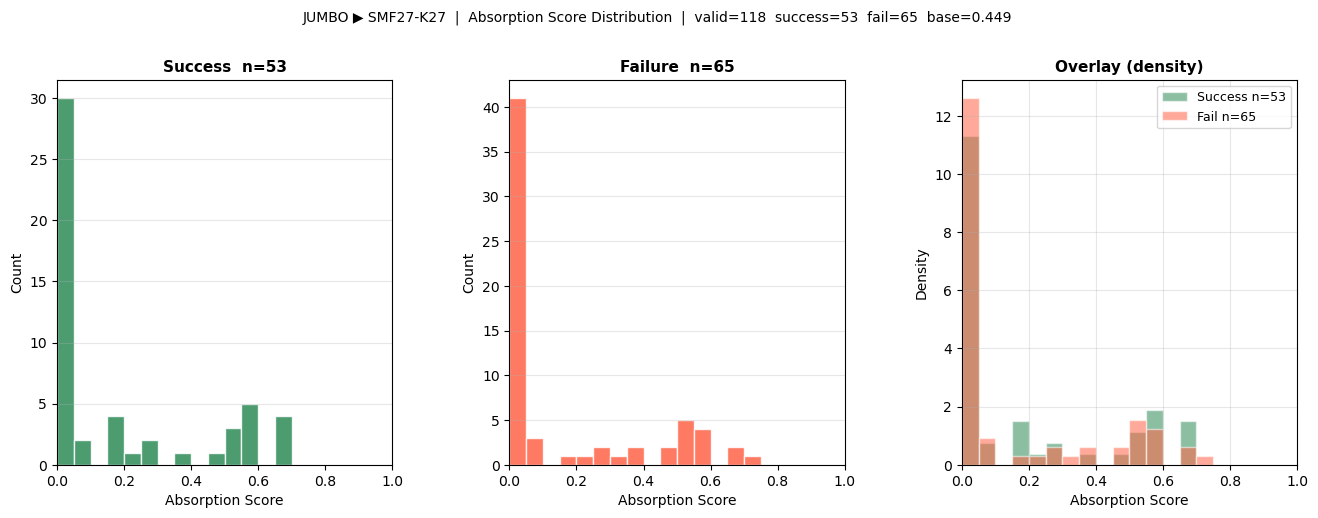

In [5]:
results_c = run_threshold_sweep(
    product_code     = PRODUCT_CODE,
    months_back      = MONTHS_BACK,
    front_n          = FRONT_N,
    score_grid       = SCORE_GRID,
    params           = V2_PARAMS,
    min_signal_count = MIN_SIGNAL_COUNT,
    n_bootstrap      = N_BOOTSTRAP,
    random_seed      = RANDOM_SEED,
    show_plots       = True,
)

## Optional — Quick result inspection

After running any of the cells above you can inspect individual instrument results here.

In [6]:
# Example: print sweep table for first instrument in Cell C results
if results_c:
    first_inst = next(iter(results_c))
    r = results_c[first_inst]
    print(f"Instrument : {first_inst}")
    print(f"Base rate  : {r['base_rate']:.3f}")
    print(f"PR-AUC     : {r['pr_auc']:.3f}")
    print()
    display(r['sweep_table'].to_string(index=False))

Instrument : SMV26-Z26
Base rate  : 0.460
PR-AUC     : 0.461



' Score Thresh  N  Precision   Prec CI 95%   Recall       F1       MCC     Lift  TP  FP  FN  TN  Low N\n         0.05 49   0.428571 [0.288,0.596] 0.304348 0.355932 -0.043922 0.931677  21  28  48  53  False\n         0.10 49   0.428571 [0.288,0.596] 0.304348 0.355932 -0.043922 0.931677  21  28  48  53  False\n         0.15 42   0.476190 [0.333,0.659] 0.289855 0.360360  0.020258 1.035197  20  22  49  59  False\n         0.20 37   0.459459 [0.311,0.658] 0.246377 0.320755 -0.000621 0.998825  17  20  52  61  False\n         0.25 33   0.515152 [0.338,0.700] 0.246377 0.333333  0.058769 1.119895  17  16  52  65  False\n         0.30 28   0.500000 [0.312,0.708] 0.202899 0.288660  0.038449 1.086957  14  14  55  67  False\n         0.35 27   0.518519 [0.333,0.740] 0.202899 0.291667  0.055011 1.127214  14  13  55  68  False\n         0.40 23   0.565217 [0.368,0.775] 0.188406 0.282609  0.089841 1.228733  13  10  56  71  False\n         0.45 16   0.500000 [0.250,0.750] 0.115942 0.188235  0.027733 1.